# TNIK v3: 접촉 검사 + 3개 시작값 + Drive 자동 저장

## 사용 방법
1. Colab에 업로드하고 GPU 런타임을 선택합니다.
2. **모두 실행**을 누르고 처음에 나오는 Google Drive 연결을 승인합니다.
3. Drive의 `TNIK_runs/TNIK_v3_run1`에서 `STATUS.json`을 확인합니다.
4. `complete`는 후속 평가 완료, `no_contact_candidate`는 접촉 검사 통과 후보 없이 탐색 종료입니다.

이 코드는 속도 확인용 16회 버전보다 탐색을 늘립니다. 몇 시간 안에 끝난다는 보장은 없습니다.
Colab GPU 할당/연결 종료를 막는 기능은 없습니다. 컴퓨터를 꺼도 계속 실행된다고 보장하지 않습니다.
중단되면 같은 설정과 폴더 이름으로 위에서부터 재실행합니다. 저장한 서열에서 warm restart합니다.
최적화 내부 상태까지 동일하게 복원하지 않으며, 저장 사이 계산은 다시 해야 합니다.

**핵심 변경:** 단백질과 떨어진 설계는 MPNN에 넘기지 않습니다. 접촉 검사도 결합·억제·IPF 효능을 입증하지 않습니다.
GPU에서 전체 계산은 아직 검증하지 않았습니다. 이 코드는 연구용 탐색이며 성공 후보를 보장하지 않습니다.

## 출처와 중요한 가정
- 원본 실습: https://github.com/jyryu3161/2026_abp/blob/dfab18ffc14c1e8a32839340735d0bfb8b9ef8c4/Lab02_MDMX_denovo_binder_design.ipynb
- 설계 도구: https://github.com/sokrypton/ColabDesign/tree/8fd167defd1b0f98e29f00584ff4f3987e6935dc
- 참고 구조: https://www.rcsb.org/structure/9XW0
- TK7 논문: https://doi.org/10.1002/anie.2417165

9XW0 author chain A(TNIK), B(TK7)를 기본 사용합니다. mmCIF label chain C는 author B와 다릅니다.
TNIK의 인산화 잔기 TPO는 일반 AlphaFold 입력에 넣을 수 없어 **THR로 치환하고 인산기 원자를 제거**합니다.
따라서 실제 인산화 상태를 재현한 계산이 아닙니다. 이 가정은 preparation.json에 남깁니다.
표적의 결손 좌표는 새로 만들지 않고 번호의 공백을 유지합니다. 물·이온은 계산 표적에서 제외합니다.
원본 mmCIF는 그대로 보존합니다. 표시된 접촉은 수소결합이나 결합 에너지의 증거가 아닙니다.

In [ ]:
#@title 1. 설정 (처음에는 그대로 실행)
from pathlib import Path
import datetime, json, random, sys, subprocess
PDB_ID = '9XW0'
TARGET_CHAIN = 'A'     # author 체인 ID: TNIK
PEPTIDE_CHAIN = 'B'    # author 체인 ID: TK7, 위치 참고용
RANDOM_SEED = 0        #@param {type:"integer"}
BINDER_LENGTH = 16     #@param {type:"integer"}
N_MPNN = 8             #@param {type:"integer"}
N_VALIDATE = 4         #@param {type:"integer"}
FAST_MODE = True       #@param {type:"boolean"}
CONTACT_CUTOFF = 5.0
N_HOTSPOT = 6
MPNN_TEMPERATURE = 0.1
ALLOW_TPO_TO_THR = True  # 위 설명의 비인산화 근사 사용
PASS_RMSD, PASS_PLDDT, PASS_IPTM = 2.0, 0.70, 0.50
# 교육용 탐색 필터: TNIK 결합/억제 예측의 검증된 경계값이 아닙니다.
assert 8 <= BINDER_LENGTH <= 40, '이 실습에서는 8~40 aa로 설정하세요.'
assert 1 <= N_VALIDATE <= N_MPNN <= 64
SOFT_ITERS, ANNEAL_ITERS, HARD_ITERS = 60, 20, 12
SEEDS = [0, 1, 2]
CHUNK = 5
HARD_TRIES = 4
MIN_BINDER_CONTACTS, MIN_HOTSPOT_CONTACTS = 3, 2
MAX_SINGLE_AA_FRACTION, MIN_UNIQUE_AA = 0.6, 5
# These are exploratory quality-control settings, not validated affinity cutoffs.
BASE = Path('/content') if Path('/content').exists() else Path.cwd()
from google.colab import drive
drive.mount('/content/drive')
RUN_NAME = 'TNIK_v3_run1'  # 재개할 때 같은 이름 사용
assert RUN_NAME and all(c.isalnum() or c in '_-' for c in RUN_NAME)
RUN_DIR = Path('/content/drive/MyDrive/TNIK_runs') / RUN_NAME
RUN_DIR.mkdir(parents=True,exist_ok=True)
print('결과 폴더:', RUN_DIR)
try:
    print(subprocess.check_output(['nvidia-smi','--query-gpu=name,memory.total','--format=csv,noheader'],text=True))
except Exception as e:
    raise RuntimeError('GPU 런타임으로 변경한 뒤 다시 실행하세요.') from e

Mounted at /content/drive
결과 폴더: /content/drive/MyDrive/TNIK_runs/TNIK_v3_run1
Tesla T4, 15360 MiB



In [ ]:
#@title 2. 도구 설치 (첫 실행에서 다운로드가 큽니다)
import importlib.metadata, urllib.request, tarfile
COLABDESIGN_COMMIT = '8fd167defd1b0f98e29f00584ff4f3987e6935dc'
subprocess.check_call([sys.executable,'-m','pip','-q','install','--no-deps',
    'git+https://github.com/sokrypton/ColabDesign.git@'+COLABDESIGN_COMMIT])
subprocess.check_call([sys.executable,'-m','pip','-q','install',
    'py3Dmol','absl-py','biopython','chex','dm-haiku','dm-tree','immutabledict',
    'ml-collections','optax','joblib','pandas','matplotlib','scipy'])
PARAM_ROOT = BASE / 'tnik_af2_parameters'
(PARAM_ROOT/'params').mkdir(parents=True,exist_ok=True)
marker = PARAM_ROOT / '.complete'
if not marker.exists():
    archive = PARAM_ROOT / 'af2_parameters.tar'
    urllib.request.urlretrieve('https://storage.googleapis.com/alphafold/alphafold_params_2022-12-06.tar',archive)
    with tarfile.open(archive) as tf:
        tf.extractall(PARAM_ROOT/'params',filter='data')
    expected = [PARAM_ROOT/'params'/f'params_model_{i}_ptm.npz' for i in range(1,6)]
    assert all(p.exists() for p in expected), '모델 파일 배치를 확인하세요'
    marker.write_text(COLABDESIGN_COMMIT)
    archive.unlink()
print('설치 완료')

설치 완료


In [ ]:
#@title 3. GPU와 실행 환경 기록
import jax, numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
if not any(d.platform=='gpu' for d in jax.devices()):
    raise RuntimeError('JAX가 GPU를 인식하지 못했습니다. 설계를 시작하지 않습니다.')
config = {k:globals()[k] for k in ['PDB_ID','TARGET_CHAIN','PEPTIDE_CHAIN','RANDOM_SEED',
    'BINDER_LENGTH','N_MPNN','N_VALIDATE','FAST_MODE','CONTACT_CUTOFF','N_HOTSPOT',
    'MPNN_TEMPERATURE','ALLOW_TPO_TO_THR','PASS_RMSD','PASS_PLDDT','PASS_IPTM',
    'SOFT_ITERS','HARD_ITERS','COLABDESIGN_COMMIT']}
config['workflow_version']='v3-contact-gated'
config.update({k:globals()[k] for k in ['ANNEAL_ITERS','SEEDS','CHUNK','HARD_TRIES',
    'MIN_BINDER_CONTACTS','MIN_HOTSPOT_CONTACTS','MAX_SINGLE_AA_FRACTION','MIN_UNIQUE_AA']})
config['design_model_names']=['model_1_ptm']
settings_path=RUN_DIR/'settings.json'
if settings_path.exists() and json.loads(settings_path.read_text(encoding='utf-8'))!=config:
    raise ValueError('이 폴더에 다른 설정이 있습니다. 1번 셀의 RUN_NAME을 바꿔 새 폴더를 사용하세요.')
settings_path.write_text(json.dumps(config,indent=2),encoding='utf-8')
(RUN_DIR/'environment.txt').write_text(subprocess.check_output(
    [sys.executable,'-m','pip','freeze'],text=True),encoding='utf-8')
print(jax.devices())

[CudaDevice(id=0)]


## 4. TNIK 구조 준비
다음 셀은 재사용 가능한 전처리 함수입니다. 내용을 바꿀 필요는 없습니다.
원본 구조의 TK7 중원자와 TNIK 사이 접촉으로 후보 결합 위치를 찾습니다.
접촉 수 상위 잔기는 **설계 위치를 정하는 휴리스틱**이며 실험적 핵심 잔기라는 뜻은 아닙니다.

In [ ]:
"""Prepare a canonical TNIK target and TK7-derived contact sites, not a TK7 model."""
from pathlib import Path
import csv
import hashlib
import json
import numpy as np
from Bio.PDB import MMCIFParser, PDBIO, Structure, Model, Chain, Residue
from Bio.PDB.MMCIF2Dict import MMCIF2Dict
from Bio.SeqUtils import seq1

AA_ATOMS = {
 'ALA':'N CA C O CB','ARG':'N CA C O CB CG CD NE CZ NH1 NH2',
 'ASN':'N CA C O CB CG OD1 ND2','ASP':'N CA C O CB CG OD1 OD2',
 'CYS':'N CA C O CB SG','GLN':'N CA C O CB CG CD OE1 NE2',
 'GLU':'N CA C O CB CG CD OE1 OE2','GLY':'N CA C O',
 'HIS':'N CA C O CB CG ND1 CD2 CE1 NE2','ILE':'N CA C O CB CG1 CG2 CD1',
 'LEU':'N CA C O CB CG CD1 CD2','LYS':'N CA C O CB CG CD CE NZ',
 'MET':'N CA C O CB CG SD CE','PHE':'N CA C O CB CG CD1 CD2 CE1 CE2 CZ',
 'PRO':'N CA C O CB CG CD','SER':'N CA C O CB OG','THR':'N CA C O CB OG1 CG2',
 'TRP':'N CA C O CB CG CD1 CD2 NE1 CE2 CE3 CZ2 CZ3 CH2',
 'TYR':'N CA C O CB CG CD1 CD2 CE1 CE2 CZ OH','VAL':'N CA C O CB CG1 CG2'
}

def _write_csv(path, rows):
    if not rows:
        raise ValueError(f'Empty table: {path}')
    with open(path, 'w', newline='', encoding='utf-8') as f:
        writer = csv.DictWriter(f, fieldnames=list(rows[0]))
        writer.writeheader(); writer.writerows(rows)

def _atoms(residue):
    """Choose one atom per name (highest occupancy conformer), exclude H/D."""
    result = []
    for item in residue:
        choices = item.disordered_get_list() if item.is_disordered() == 2 else [item]
        atom = max(choices, key=lambda a: (a.get_occupancy() or 0, a.altloc == 'A'))
        if atom.element not in ('H', 'D'):
            result.append(atom)
    return result

def prepare_tnik(cif_path, out_dir, target_chain='A', peptide_chain='B', cutoff=5.0,
                 n_hotspots=6, allow_tpo_to_thr=True):
    """Chain arguments use author IDs. Output PDB A uses label_seq_id numbering.

    No gap filling, cropping, TK7 linearization, phosphate force field or assembly inference.
    Contacts use original heavy atoms, including phosphate and modified peptide atoms.
    """
    if cutoff <= 0 or n_hotspots < 1:
        raise ValueError('cutoff > 0 and n_hotspots >= 1 required')
    cif_path, out_dir = Path(cif_path), Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    d = MMCIF2Dict(str(cif_path))
    entity_names = dict(zip(d['_entity.id'], d['_entity.pdbx_description']))
    atom_keys = ['auth_asym_id','label_asym_id','label_entity_id','auth_seq_id',
                 'label_seq_id','pdbx_PDB_ins_code','label_comp_id']
    atom_rows = list(zip(*(d['_atom_site.'+key] for key in atom_keys)))
    chain_entities = {}
    sequence_ids = {}
    for auth, label, eid, auth_num, label_num, ins, name in atom_rows:
        if label_num in ('.','?'):
            continue
        chain_entities.setdefault(auth, {'label':label,'entity_id':eid,
                                         'description':entity_names[eid]})
        sequence_ids[(auth, int(auth_num), '' if ins in ('.','?') else ins)] = int(label_num)
    for chain, keyword in [(target_chain,'interacting'),(peptide_chain,'TK7')]:
        if chain not in chain_entities or keyword.lower() not in chain_entities[chain]['description'].lower():
            raise ValueError(f'Unexpected chain {chain}: {chain_entities}. Check author chain IDs.')
    source = MMCIFParser(QUIET=True, auth_chains=True, auth_residues=True).get_structure('9XW0', str(cif_path))
    target = [r for r in source[0][target_chain] if (target_chain,r.id[1],r.id[2].strip()) in sequence_ids]
    peptide = [r for r in source[0][peptide_chain] if (peptide_chain,r.id[1],r.id[2].strip()) in sequence_ids]
    if not target or not peptide:
        raise ValueError('Missing target or peptide polymer coordinates')
    peptide_atoms = [(r,a) for r in peptide for a in _atoms(r)]
    xyz = np.array([a.coord for r,a in peptide_atoms])
    structure = Structure.Structure('TNIK_canonical')
    model = Model.Model(0); chain = Chain.Chain('A')
    structure.add(model); model.add(chain)
    mapping, contact_rows, changes = [], [], []
    for r in target:
        original = r.resname
        name = {'TPO':'THR'}.get(original, original)
        if original == 'TPO' and not allow_tpo_to_thr:
            raise ValueError('TPO cannot be represented by this AF2 workflow. Explicit TPO->THR approximation required.')
        if name not in AA_ATOMS or not all(a in r for a in ('N','CA','C','O')):
            raise ValueError(f'Unsupported/incomplete TNIK residue: {r.id} {original}')
        new_id = sequence_ids[(target_chain,r.id[1],r.id[2].strip())]
        nr = Residue.Residue((' ',new_id,' '),name,' ')
        allowed = set(AA_ATOMS[name].split())
        for atom in _atoms(r):
            if atom.name in allowed:
                copied = atom.copy(); copied.set_altloc(' '); copied.disordered_flag=0
                nr.add(copied)
        chain.add(nr)
        mapping.append({'design_chain':'A','design_resseq':new_id,'auth_chain':target_chain,
                        'auth_resseq':r.id[1],'auth_icode':r.id[2].strip(),
                        'original_resname':original,'model_resname':name})
        if original != name:
            changes.append({'auth_resseq':r.id[1], 'design_resseq':new_id,
                            'change':f'{original}->{name}',
                            'removed_atoms':[a.name for a in _atoms(r) if a.name not in allowed]})
        tx = np.array([a.coord for a in _atoms(r)])
        distances = np.sqrt(((tx[:,None,:]-xyz[None,:,:])**2).sum(-1))
        close = distances.min(axis=0) < cutoff
        partners = {rr.id for (rr,aa),flag in zip(peptide_atoms,close) if flag}
        if partners:
            contact_rows.append({'design_resseq':new_id,'auth_resseq':r.id[1],
                                 'original_resname':original,
                                 'min_distance_A':round(float(distances.min()),3),
                                 'n_peptide_partners':len(partners)})
    if not contact_rows:
        raise ValueError('No contacts: wrong pair of chains or cutoff')
    contact_rows.sort(key=lambda x:(-x['n_peptide_partners'],x['min_distance_A'],x['design_resseq']))
    hotspots = sorted(row['design_resseq'] for row in contact_rows[:n_hotspots])
    io = PDBIO(); io.set_structure(structure); io.save(str(out_dir/'target.pdb'))
    _write_csv(out_dir/'residue_mapping.csv',mapping)
    _write_csv(out_dir/'reference_contacts.csv',contact_rows)
    ids = [r['design_resseq'] for r in mapping]
    gaps = sorted(set(range(min(ids),max(ids)+1))-set(ids))
    def missing_positions(author_chain, observed):
        eid = chain_entities[author_chain]['entity_id']
        declared = {int(n) for e,n in zip(d['_entity_poly_seq.entity_id'],d['_entity_poly_seq.num']) if e==eid}
        seen = {sequence_ids[(author_chain,r.id[1],r.id[2].strip())] for r in observed}
        return len(declared),sorted(declared-seen)
    target_total,target_missing = missing_positions(target_chain,target)
    reference_total,reference_missing = missing_positions(peptide_chain,peptide)
    report = {'pdb_id':'9XW0','source_sha256':hashlib.sha256(cif_path.read_bytes()).hexdigest(),
              'author_target_chain':target_chain,'author_peptide_chain':peptide_chain,
              'chain_inventory':chain_entities,'n_target_residues':len(mapping),
              'n_reference_residues':len(peptide),'missing_internal_label_positions':gaps,
              'target_declared_residues':target_total,'target_missing_label_positions':target_missing,
              'reference_declared_residues':reference_total,'reference_missing_label_positions':reference_missing,
              'hotspot_string':','.join(map(str,hotspots)), 'contact_cutoff_A':cutoff,
              'target_sequence_observed':''.join(seq1(r.resname) for r in chain),
              'chemical_approximations':changes,
              'limitations':['Canonical linear de novo binder design, not TK7 redesign.',
                            'Original mmCIF is authoritative; TK7 bond chemistry is not modeled.',
                            'TPO->THR removes phosphate; native phosphorylated TNIK is not reproduced.',
                            'Contact-count hotspots are heuristic, not experimentally proven energetic hotspots.',
                            'Missing coordinates are not rebuilt; missing terminal residues also possible.']}
    (out_dir/'preparation.json').write_text(json.dumps(report,ensure_ascii=False,indent=2),encoding='utf-8')
    return report

In [ ]:
#@title 4a. 구조 다운로드와 전처리
from urllib.request import urlretrieve
CIF_PATH = RUN_DIR/'9XW0_original.cif'
if not CIF_PATH.exists():
    urlretrieve('https://files.rcsb.org/download/9XW0.cif',CIF_PATH)
report = prepare_tnik(CIF_PATH,RUN_DIR,TARGET_CHAIN,PEPTIDE_CHAIN,
                      CONTACT_CUTOFF,N_HOTSPOT,ALLOW_TPO_TO_THR)
HOTSPOT_STR=report['hotspot_string']
TARGET_PDB=str(RUN_DIR/'target.pdb')
print('TNIK 좌표 잔기 수:',report['n_target_residues'])
print('참고 TK7 좌표 잔기 수:',report['n_reference_residues'])
print('TK7 미해결 위치:',report['reference_missing_label_positions'])
print('주의: 결합 위치 추출은 좌표가 있는 TK7 원자에 한정됩니다.')
print('설계 위치 (계산용 PDB 번호):',HOTSPOT_STR)
print('화학적 단순화:',report['chemical_approximations'])
print('복원하지 않은 내부 결손 위치:',report['missing_internal_label_positions'])
print('말단 포함 전체 TNIK 결손 위치:',report['target_missing_label_positions'])
display(pd.read_csv(RUN_DIR/'reference_contacts.csv').head(12))
import hashlib
prep_hash=hashlib.sha256((RUN_DIR/'target.pdb').read_bytes()).hexdigest()
signature_path=RUN_DIR/'target_signature.txt'
signature=prep_hash+'|'+HOTSPOT_STR
if signature_path.exists() and signature_path.read_text()!=signature:
    raise ValueError('저장된 표적과 현재 전처리가 다릅니다. 새 RUN_NAME을 사용하세요.')
signature_path.write_text(signature)

TNIK 좌표 잔기 수: 299
참고 TK7 좌표 잔기 수: 14
TK7 미해결 위치: [1, 2]
주의: 결합 위치 추출은 좌표가 있는 TK7 원자에 한정됩니다.
설계 위치 (계산용 PDB 번호): 182,184,185,226,229,230
화학적 단순화: [{'auth_resseq': 181, 'design_resseq': 173, 'change': 'TPO->THR', 'removed_atoms': ['P', 'O1P', 'O2P', 'O3P']}, {'auth_resseq': 187, 'design_resseq': 179, 'change': 'TPO->THR', 'removed_atoms': ['P', 'O1P', 'O2P', 'O3P']}]
복원하지 않은 내부 결손 위치: []
말단 포함 전체 TNIK 결손 위치: [1, 2, 3, 303, 304, 305, 306]


,design_resseq,auth_resseq,original_resname,min_distance_A,n_peptide_partners
0,230,238,PRO,3.203,5
1,185,193,TYR,3.225,4
2,229,237,HIS,3.386,4
3,226,234,CYS,2.032,3
4,182,190,GLY,3.255,3
5,184,192,PRO,3.395,3
6,183,191,THR,3.453,3
7,27,35,THR,3.626,3
8,147,155,LYS,3.669,3
9,57,65,GLU,3.086,2


88

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

주황색 = 참고 TK7. 이 그림은 원본 좌표 표시이며 화학결합 검증 도구는 아닙니다.


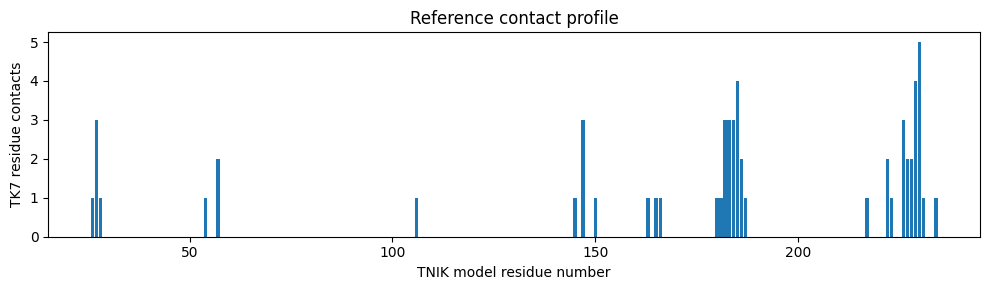

In [ ]:
#@title 4b. 실제 TNIK-TK7 구조 보기
import py3Dmol
v=py3Dmol.view(width=850,height=480)
v.addModel(CIF_PATH.read_text(),'mmcif')
v.setStyle({}, {'cartoon':{'color':'lightgray'}})
v.setStyle({'chain':PEPTIDE_CHAIN},{'stick':{'color':'orange'}})
v.zoomTo({'chain':PEPTIDE_CHAIN}); v.show()
print('주황색 = 참고 TK7. 이 그림은 원본 좌표 표시이며 화학결합 검증 도구는 아닙니다.')
contacts=pd.read_csv(RUN_DIR/'reference_contacts.csv')
fig,ax=plt.subplots(figsize=(10,3))
ax.bar(contacts.design_resseq,contacts.n_peptide_partners)
ax.set(xlabel='TNIK model residue number',ylabel='TK7 residue contacts',title='Reference contact profile')
fig.tight_layout();fig.savefig(RUN_DIR/'reference_contacts.png',dpi=160);plt.show()

## 5. 충분한 탐색 후 접촉 검사
각 시작값에서 soft 60회 → 온도 감소 20회 → 변이 탐색 12회(회당 4개 시도)를 수행합니다.
설계 목적함수의 접촉 거리도 8 Å로 명시합니다. 8 Å 목적함수와 별도로 5 Å 실제 원자 접촉을 검사합니다.
hard 단계 저장 구조에서 펩타이드 잔기 3개 이상, 지정 hotspot 2개 이상이 5 Å 이내 접촉해야 합니다.
원자 간 1.8 Å 미만 충돌이 있거나 서열 반복이 과도하면 제외합니다. 임시 품질 기준일 뿐입니다.
각 seed의 검사 통과 구조 중 모델 확신도가 높은 것을 비교해 **한 설계 골격**을 후속 평가합니다.
통과 구조가 없으면 이유를 저장하고 종료합니다. 후속 평가에는 최대 한 골격만 사용합니다.

In [ ]:
#@title 5a. 여러 시작값 탐색, 접촉 검사, 자동 저장
import time, os, gc, collections
from Bio.PDB import PDBParser
from colabdesign import mk_afdesign_model, clear_mem

def atomic_text(path,text):
    path=Path(path);temp=Path(str(path)+'.tmp')
    temp.write_text(text,encoding='utf-8');os.replace(temp,path)
def status(stage,**kwargs):
    atomic_text(RUN_DIR/'STATUS.json',json.dumps({'stage':stage,'updated_at':
        datetime.datetime.now(datetime.timezone.utc).isoformat(),**kwargs},ensure_ascii=False,indent=2))

mapping=pd.read_csv(RUN_DIR/'residue_mapping.csv')
# ColabDesign output PDB renumbers observed target residues from 1.
hotspot_indices={i+1 for i,row in mapping.iterrows() if int(row.design_resseq) in set(map(int,HOTSPOT_STR.split(',')))}

def structure_gate(path,sequence):
    st=PDBParser(QUIET=True).get_structure('gate',str(path))[0]
    a=[x for x in st['A'].get_atoms() if x.element not in ('H','D')]
    b=[x for x in st['B'].get_atoms() if x.element not in ('H','D')]
    if not a or not b:raise ValueError('Empty protein or binder chain')
    d=np.sqrt(((np.array([x.coord for x in a])[:,None,:]-np.array([x.coord for x in b])[None,:,:])**2).sum(-1))
    ii,jj=np.where(d<5.0)
    target_contacts={a[i].parent.id[1] for i in ii}
    binder_contacts={b[j].parent.id[1] for j in jj}
    fraction=max(collections.Counter(sequence).values())/len(sequence)
    reasons=[]
    if len(binder_contacts)<MIN_BINDER_CONTACTS:reasons.append('insufficient_binder_contacts')
    if len(target_contacts & hotspot_indices)<MIN_HOTSPOT_CONTACTS:reasons.append('wrong_or_insufficient_target_site_contacts')
    if (d<1.8).any():reasons.append('severe_interchain_clash')
    if fraction>MAX_SINGLE_AA_FRACTION or len(set(sequence))<MIN_UNIQUE_AA:reasons.append('low_sequence_complexity')
    return dict(gate_pass=not reasons,reasons=reasons,min_distance_A=float(d.min()),
        binder_contact_residues=len(binder_contacts),hotspot_contacts=len(target_contacts & hotspot_indices),
        maximum_single_aa_fraction=fraction,unique_amino_acids=len(set(sequence)))

def checkpoint(model,folder,phase,done,best):
    seq=model.get_seq(get_best=False)[0]
    filename=f'{phase}_{done:03d}.pdb'
    path=folder/filename;temp=Path(str(path)+'.tmp')
    model.save_pdb(str(temp),get_best=False);os.replace(temp,path)
    metrics=structure_gate(path,seq)
    confidence=float(model.aux['log']['i_ptm'])
    if phase=='hard' and metrics['gate_pass'] and (best is None or confidence>best['ipTM']):
        best=dict(sequence=seq,pdb_file=filename,ipTM=confidence,**metrics)
    state=dict(phase=phase,done=done,sequence=seq,pdb_file=filename,metrics=metrics,best=best,
               resume='warm restart from saved sequence, not exact optimizer restoration')
    atomic_text(folder/'state.json',json.dumps(state,ensure_ascii=False,indent=2))
    print('Drive 저장:',filename,'| 접촉:',metrics['binder_contact_residues'],
          '| 목표 부위:',metrics['hotspot_contacts'],'|',','.join(metrics['reasons']) or 'contact gate passed',flush=True)
    return state

status('design_running')
qualified=[]
for seed in SEEDS:
    folder=RUN_DIR/f'seed_{seed}';folder.mkdir(exist_ok=True)
    summary_path=folder/'summary.json';state_path=folder/'state.json'
    if summary_path.exists():
        summary=json.loads(summary_path.read_text(encoding='utf-8'))
        print('기존 seed 결과 재사용:',seed,flush=True)
        if summary['best']:qualified.append({**summary['best'],'folder':str(folder),'seed':seed})
        continue
    saved=json.loads(state_path.read_text(encoding='utf-8')) if state_path.exists() else None
    best=saved['best'] if saved else None
    model=None
    try:
        print('시작값',seed,'모델 준비 / 첫 계산 컴파일은 오래 걸릴 수 있습니다.',flush=True)
        clear_mem()
        model=mk_afdesign_model(protocol='binder',data_dir=str(PARAM_ROOT),
            model_names=['model_1_ptm'],num_recycles=0,recycle_mode='last')
        model.prep_inputs(pdb_filename=TARGET_PDB,target_chain='A',binder_len=BINDER_LENGTH,hotspot=HOTSPOT_STR)
        model.restart(seed=seed,seq=saved['sequence'] if saved else None,rm_aa='C')
        model.set_weights(i_con=2.0,i_pae=0.1)
        model.set_opt('i_con',cutoff=8.0,num=2)
        phases=[('soft',SOFT_ITERS),('anneal',ANNEAL_ITERS),('hard',HARD_ITERS)]
        for phase_index,(phase,total) in enumerate(phases):
            saved_phase=next((i for i,p in enumerate(phases) if saved and p[0]==saved['phase']),-1)
            if phase_index<saved_phase:continue
            done=saved['done'] if phase_index==saved_phase else 0
            while done<total:
                amount=1 if phase=='hard' else min(CHUNK,total-done)
                status('design_running',seed=seed,phase=phase,completed=done,total=total)
                print(f'Seed {seed} | {phase}: {done+1}~{done+amount}/{total} 시작',flush=True)
                common=dict(num_recycles=0,num_models=1,sample_models=False,save_best=False,verbose=1)
                if phase=='soft':model.design_soft(iters=amount,temp=1.0,dropout=False,**common)
                elif phase=='anneal':
                    t0=max(0.05,1.0-0.95*done/total);t1=max(0.05,1.0-0.95*(done+amount)/total)
                    model.design(iters=amount,soft=1,temp=t0,e_temp=t1,dropout=False,**common)
                else:model.design_semigreedy(iters=amount,tries=HARD_TRIES,dropout=False,**common)
                done+=amount
                saved=checkpoint(model,folder,phase,done,best);best=saved['best']
        summary={'seed':seed,'best':best,'status':'finished','final_gate':saved['metrics']}
        atomic_text(summary_path,json.dumps(summary,ensure_ascii=False,indent=2))
        if best:qualified.append({**best,'folder':str(folder),'seed':seed})
    except KeyboardInterrupt:
        status('interrupted',seed=seed);raise
    except Exception as exc:
        status('error',seed=seed,message=f'{type(exc).__name__}: {exc}')
        # Keep the error visible; do not silently proceed after a model/API/resource failure.
        raise
    finally:
        if model is not None:del model
        gc.collect();clear_mem()

atomic_text(RUN_DIR/'design_gate_summary.json',json.dumps(qualified,ensure_ascii=False,indent=2))
if not qualified:
    status('no_contact_candidate',message='All seeds finished; no hard-stage structure passed contact and sequence checks.')
    import shutil
    diagnostic_zip=shutil.make_archive(str(RUN_DIR.parent/(RUN_NAME+'_results')),'zip',RUN_DIR)
    print('진단 결과 ZIP을 Drive에 저장했습니다:',diagnostic_zip,flush=True)
    raise RuntimeError('탐색 종료: 접촉·서열 검사 통과 후보가 없습니다. 오류로 계산이 실패한 것이 아닙니다. Drive의 seed별 summary.json을 확인하세요. 후속 계산은 생략합니다.')
winner=max(qualified,key=lambda r:r['ipTM'])
DESIGN_PDB=str(RUN_DIR/'design.pdb');AFDESIGN_SEQ=winner['sequence']
atomic_text(DESIGN_PDB,(Path(winner['folder'])/winner['pdb_file']).read_text())
atomic_text(RUN_DIR/'selected_design.json',json.dumps(winner,ensure_ascii=False,indent=2))
status('design_contact_gate_passed',seed=winner['seed'])
print('선택된 접촉 검사 통과 설계:',AFDESIGN_SEQ,flush=True)

기존 seed 결과 재사용: 0
시작값 1 모델 준비 / 첫 계산 컴파일은 오래 걸릴 수 있습니다.
Seed 1 | soft: 31~35/60 시작
1 models [0] recycles 0 hard 0 soft 1 temp 1 loss 9.81 i_pae 0.68 i_con 4.84 plddt 0.38 ptm 0.89 i_ptm 0.23
2 models [0] recycles 0 hard 0 soft 1 temp 1 loss 9.44 i_pae 0.64 i_con 4.66 plddt 0.38 ptm 0.89 i_ptm 0.25
3 models [0] recycles 0 hard 0 soft 1 temp 1 loss 9.29 i_pae 0.63 i_con 4.58 plddt 0.37 ptm 0.89 i_ptm 0.26
4 models [0] recycles 0 hard 0 soft 1 temp 1 loss 9.28 i_pae 0.63 i_con 4.58 plddt 0.37 ptm 0.89 i_ptm 0.26
5 models [0] recycles 0 hard 0 soft 1 temp 1 loss 9.24 i_pae 0.63 i_con 4.56 plddt 0.37 ptm 0.89 i_ptm 0.27
Drive 저장: soft_035.pdb | 접촉: 5 | 목표 부위: 1 | wrong_or_insufficient_target_site_contacts
Seed 1 | soft: 36~40/60 시작
6 models [0] recycles 0 hard 0 soft 1 temp 1 loss 9.26 i_pae 0.63 i_con 4.57 plddt 0.37 ptm 0.89 i_ptm 0.27
7 models [0] recycles 0 hard 0 soft 1 temp 1 loss 9.19 i_pae 0.62 i_con 4.53 plddt 0.37 ptm 0.89 i_ptm 0.27
8 models [0] recycles 0 hard 0 soft 1 temp 1 lo

## 6. 같은 모양에 맞는 서열 후보 만들기
ProteinMPNN은 아미노산 순서를 제안합니다. 낮은 MPNN 점수는 결합력이나 억제력의 측정값이 아닙니다.
표적 TNIK 서열은 고정하고, 새 펩타이드만 바꿉니다.

In [ ]:
#@title 6. ProteinMPNN 실행
from colabdesign.mpnn import mk_mpnn_model
mpnn_path=RUN_DIR/'mpnn_all_candidates.csv'
if mpnn_path.exists():
    mpnn_df=pd.read_csv(mpnn_path)
    print('저장된 MPNN 후보를 불러왔습니다.',flush=True)
else:
    mpnn=mk_mpnn_model(seed=RANDOM_SEED)
    mpnn.prep_inputs(pdb_filename=DESIGN_PDB,chain='A,B',fix_pos='A',rm_aa='C')
    sample=mpnn.sample(num=1,batch=N_MPNN,temperature=MPNN_TEMPERATURE)
    seqs=[str(s).split('/')[-1] for s in sample['seq']]
    if not all(len(s)==BINDER_LENGTH and set(s)<=set('ACDEFGHIKLMNPQRSTVWY') for s in seqs):
        raise ValueError('MPNN 출력의 체인/서열 형식이 예상과 다릅니다.')
    mpnn_df=pd.DataFrame({'sequence':seqs,'mpnn_score':np.asarray(sample['score']).reshape(-1)})
    mpnn_df=mpnn_df.sort_values('mpnn_score').drop_duplicates('sequence').reset_index(drop=True)
    mpnn_df.to_csv(RUN_DIR/'mpnn_all_candidates.csv',index=False)
    del mpnn
mpnn_df['sequence_quality_pass']=mpnn_df.sequence.map(lambda s:
    len(set(s))>=MIN_UNIQUE_AA and max(collections.Counter(s).values())/len(s)<=MAX_SINGLE_AA_FRACTION)
mpnn_df.to_csv(RUN_DIR/'mpnn_all_candidates.csv',index=False)
display(mpnn_df)

,sequence,mpnn_score,sequence_quality_pass
0,APKPSRLNIGYVPKDG,1.487409,True
1,PPKPSRLNIGYVPKDG,1.504900,True
2,APKPSRLNIGYEPEDG,1.520896,True
3,SPKPSRLNIGYVPKSG,1.535199,True
4,APRPSRLNIGFEPLLG,1.544519,True
5,APKPSRLNLVYVPENG,1.545302,True
6,APKPSRLNIGYIPPLG,1.554880,True
7,APKPSRLNLGYIPPLG,1.572725,True


## 7. 구조 재예측과 비교
설계 후보를 다시 구조 예측해, 설계 때의 모양·결합 배치와 일관되는지 평가합니다.
이는 **동일 모델 계열의 자기 일관성 평가**입니다. 독립 검증·실제 결합 확인이 아닙니다.
고정된 TNIK 템플릿을 쓰며 binder 템플릿은 제거합니다.
RMSD는 TNIK에 정렬한 뒤 새 펩타이드의 CA 좌표를 비교해 직접 계산합니다.
서열을 섞은 대조군도 계산하지만, 실제 비결합이 입증된 음성 대조군은 아닙니다.
TK7은 이 선형 예측의 양성 대조군으로 사용하지 않습니다.

In [ ]:
#@title 7a. 재예측 (전체 결과와 후보별 구조 저장)
import gc, random
from Bio.PDB import PDBParser, Superimposer
def binder_rmsd_target_aligned(ref_path,pred_path):
    parser=PDBParser(QUIET=True)
    ref=parser.get_structure('ref',str(ref_path))[0]
    pred=parser.get_structure('pred',str(pred_path))[0]
    def ca(chain): return [r['CA'] for r in chain if 'CA' in r]
    rta,pta=ca(ref['A']),ca(pred['A'])
    rb,pb=ca(ref['B']),ca(pred['B'])
    if len(rta)!=len(pta) or len(rb)!=len(pb):
        raise ValueError('정렬할 잔기 수가 다릅니다.')
    sup=Superimposer();sup.set_atoms(rta,pta)
    rot,tran=sup.rotran
    aligned=np.array([a.coord for a in pb])@rot+tran
    return float(np.sqrt(np.mean(np.sum((aligned-np.array([a.coord for a in rb]))**2,axis=1))))

# Save model resources before releasing the design model.

gc.collect(); clear_mem()
val_model=mk_afdesign_model(protocol='binder',data_dir=str(PARAM_ROOT),model_names=['model_1_ptm'],
                            num_recycles=1,recycle_mode='last')
val_model.prep_inputs(pdb_filename=DESIGN_PDB,target_chain='A',binder_chain='B',
                      rm_binder=True,rm_binder_seq=True,rm_binder_sc=True)
mpnn_selected=mpnn_df[mpnn_df.sequence_quality_pass].head(N_VALIDATE).sequence.tolist()
selected=list(dict.fromkeys([AFDESIGN_SEQ]+mpnn_selected))
rng=random.Random(RANDOM_SEED)
controls=[]
for seq in mpnn_selected[:3]:
    for attempt in range(30):
        shuffled=''.join(rng.sample(list(seq),len(seq)))
        if shuffled not in selected and shuffled not in controls:
            controls.append(shuffled);break
candidates=[('design',s) for s in selected]+[('shuffled_control',s) for s in controls]
validation_path=RUN_DIR/'validation_all.csv'
old_rows=pd.read_csv(validation_path,keep_default_na=False).to_dict('records') if validation_path.exists() else []
rows=[]
(RUN_DIR/'predictions').mkdir(exist_ok=True)
for idx,(kind,seq) in enumerate(candidates,1):
    cid=f'TNIK_{idx:03d}'
    pred_path=RUN_DIR/'predictions'/f'{cid}.pdb'
    prior=next((r for r in old_rows if r['candidate_id']==cid and r['sequence']==seq
                and r['error']=='' and (RUN_DIR/r['structure_file']).is_file()),None)
    if prior:
        rows.append(prior)
        print(cid,'저장된 재예측을 재사용합니다.',flush=True)
        continue
    print(f'재예측 {idx}/{len(candidates)}: {cid}',flush=True)
    try:
        val_model.predict(seq=seq,num_recycles=1,num_models=1,verbose=False,seed=RANDOM_SEED)
        val_model.save_pdb(str(pred_path),get_best=False)
        rmsd=binder_rmsd_target_aligned(DESIGN_PDB,pred_path)
        # pLDDT in ColabDesign aux is normalized to 0..1.
        confidence=np.asarray(val_model.aux['plddt'])[-BINDER_LENGTH:]
        plddt=float(confidence.mean())
        iptm=float(val_model.aux['log']['i_ptm'])
        gate=structure_gate(pred_path,seq)
        if not (0<=plddt<=1 and 0<=iptm<=1):
            raise ValueError('확신도 단위가 예상과 다릅니다. 버전을 확인하세요.')
        rows.append(dict(candidate_id=cid,kind=kind,sequence=seq,
             target_aligned_binder_CA_RMSD_A=rmsd,binder_pLDDT=plddt,ipTM=iptm,
             passes_exploratory_filter=bool(rmsd<PASS_RMSD and plddt>PASS_PLDDT and iptm>PASS_IPTM and gate['gate_pass']),
             contact_gate_pass=gate['gate_pass'],contact_gate_reasons=';'.join(gate['reasons']),
             structure_file=f'predictions/{cid}.pdb',error=''))
    except Exception as exc:
        rows.append(dict(candidate_id=cid,kind=kind,sequence=seq,
             target_aligned_binder_CA_RMSD_A=np.nan,binder_pLDDT=np.nan,ipTM=np.nan,
             passes_exploratory_filter=False,structure_file='',contact_gate_pass=False,contact_gate_reasons='prediction_error',error=f'{type(exc).__name__}: {exc}'))
        print(cid,'실패:',exc)
    status('validation_running',candidate=cid,completed=len(rows),total=len(candidates))
    # Keep partial results even if the runtime later stops.
    pd.DataFrame(rows).to_csv(RUN_DIR/'validation_all.csv.tmp',index=False)
    os.replace(RUN_DIR/'validation_all.csv.tmp',validation_path)
val_df=pd.DataFrame(rows)
val_df.to_csv(RUN_DIR/'validation_all.csv.tmp',index=False)
os.replace(RUN_DIR/'validation_all.csv.tmp',validation_path)
display(val_df)
if not (val_df.error=='').any():
    status('validation_failed',message='All predictions failed; see validation_all.csv error column')
    raise RuntimeError('모든 재예측이 실패했습니다. error 열을 확인하세요.')

재예측 1/8: TNIK_001
재예측 2/8: TNIK_002
재예측 3/8: TNIK_003
재예측 4/8: TNIK_004
재예측 5/8: TNIK_005
재예측 6/8: TNIK_006
재예측 7/8: TNIK_007
재예측 8/8: TNIK_008


,candidate_id,kind,sequence,target_aligned_binder_CA_RMSD_A,binder_pLDDT,ipTM,passes_exploratory_filter,contact_gate_pass,contact_gate_reasons,structure_file,error
0,TNIK_001,design,KRKRIRLMLEMQDPRV,2.115195,0.358591,0.376969,False,True,,predictions/TNIK_001.pdb,
1,TNIK_002,design,APKPSRLNIGYVPKDG,2.741176,0.331059,0.257037,False,True,,predictions/TNIK_002.pdb,
2,TNIK_003,design,PPKPSRLNIGYVPKDG,3.310636,0.328188,0.233035,False,False,insufficient_binder_contacts;wrong_or_insuffic...,predictions/TNIK_003.pdb,
3,TNIK_004,design,APKPSRLNIGYEPEDG,23.109111,0.303314,0.171786,False,False,insufficient_binder_contacts;wrong_or_insuffic...,predictions/TNIK_004.pdb,
4,TNIK_005,design,SPKPSRLNIGYVPKSG,3.013852,0.333518,0.262721,False,True,,predictions/TNIK_005.pdb,
5,TNIK_006,shuffled_control,PGLASINKVPKGPRDY,53.820541,0.336466,0.117204,False,False,insufficient_binder_contacts;wrong_or_insuffic...,predictions/TNIK_006.pdb,
6,TNIK_007,shuffled_control,SPPGGIDKVPRLYKNP,25.217544,0.323444,0.238290,False,False,wrong_or_insufficient_target_site_contacts,predictions/TNIK_007.pdb,
7,TNIK_008,shuffled_control,ERGYPINGSAPLDKPE,59.514745,0.366804,0.122369,False,False,insufficient_binder_contacts;wrong_or_insuffic...,predictions/TNIK_008.pdb,


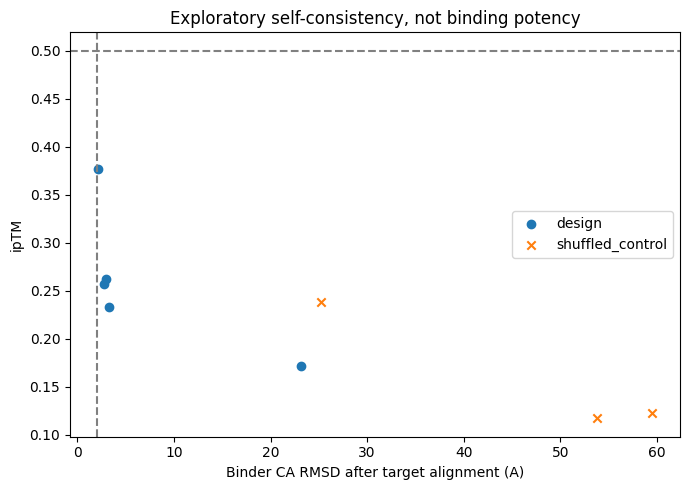

In [ ]:
#@title 7b. 결과 그림 (전체 표를 덮어쓰지 않습니다)
fig,ax=plt.subplots(figsize=(7,5))
for kind,color,marker in [('design','tab:blue','o'),('shuffled_control','tab:orange','x')]:
    sub=val_df[(val_df.kind==kind)&(val_df.error=='')]
    ax.scatter(sub.target_aligned_binder_CA_RMSD_A,sub.ipTM,label=kind,c=color,marker=marker)
ax.axvline(PASS_RMSD,c='gray',ls='--');ax.axhline(PASS_IPTM,c='gray',ls='--')
ax.set(xlabel='Binder CA RMSD after target alignment (A)',ylabel='ipTM',
       title='Exploratory self-consistency, not binding potency')
ax.legend();fig.tight_layout();fig.savefig(RUN_DIR/'validation.png',dpi=160);plt.show()

In [ ]:
#@title 8. 후보 정리와 결과 다운로드
import shutil
final=val_df[(val_df.kind=='design')&val_df.passes_exploratory_filter&(val_df.error=='')].copy()
final=final.sort_values(['target_aligned_binder_CA_RMSD_A','ipTM'],ascending=[True,False])
final.to_csv(RUN_DIR/'tnik_prioritized_candidates.csv',index=False)
with open(RUN_DIR/'tnik_prioritized_candidates.fasta','w') as f:
    for row in final.itertuples():
        f.write(f'>{row.candidate_id} computational_candidate_only\n{row.sequence}\n')
status('complete',evaluated=len(val_df),prioritized=len(final))
print('탐색 필터 통과 수:',len(final))
display(final)
(RUN_DIR/'READ_ME_FIRST.txt').write_text(
    'TNIK de novo linear binder exploration. Not TK7 bicyclic redesign.\n'
    'No experimentally validated binding, kinase inhibition or IPF benefit.\n'
    'TPO->THR approximation; inspect preparation.json and residue_mapping.csv.\n'
    'All evaluated candidates, controls and failures: validation_all.csv.\n'
    'Unvalidated MPNN proposals: mpnn_all_candidates.csv.\n'
    'Filtering cutoffs are educational heuristics, not potency estimates.\n',encoding='utf-8')
archive=shutil.make_archive(str(BASE/(RUN_NAME+'_results')),'zip',RUN_DIR)
shutil.copy2(archive,RUN_DIR.parent/(RUN_NAME+'_results.zip'))
print('결과 ZIP을 Drive에도 저장했습니다:',RUN_DIR.parent/(RUN_NAME+'_results.zip'))
print('결과:',archive)
try:
    from google.colab import files
    files.download(archive)
except ImportError:
    print('Colab 밖에서는 위 경로에서 ZIP을 열어주세요.')

탐색 필터 통과 수: 0


,candidate_id,kind,sequence,target_aligned_binder_CA_RMSD_A,binder_pLDDT,ipTM,passes_exploratory_filter,contact_gate_pass,contact_gate_reasons,structure_file,error


결과 ZIP을 Drive에도 저장했습니다: /content/drive/MyDrive/TNIK_runs/TNIK_v3_run1_results.zip
결과: /content/TNIK_v3_run1_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 결과를 어떻게 읽나요?
- `reference_contacts.csv`: 실제 참고 구조에서 TK7과 가까운 TNIK 잔기. 결합 에너지 측정값은 아닙니다.
- `residue_mapping.csv`: 원래 구조 번호와 계산용 번호 대응표.
- `preparation.json`: 인산화 제거·결손 등 구조 전처리의 가정.
- `mpnn_all_candidates.csv`: 생성한 전체 서열. 일부만 재예측합니다.
- `validation_all.csv`: 재예측한 모든 후보·섞은 대조군·실패 기록.
- `tnik_prioritized_candidates.csv/.fasta`: 교육용 필터를 통과한 계산 후보. 비어 있을 수 있습니다.
- `predictions/`: 후보별 재예측 구조. 설계 골격 `design.pdb`와 구분합니다.

**보고서 표현:** “TK7 결합면을 참고해 새로운 선형 펩타이드를 계산 설계하고,
구조 자기 일관성에 따라 후속 검증 후보를 제안했다.”
“TNIK 억제제 개발 성공”이나 “IPF 치료 효과 확인”으로 쓰지 않습니다.
다른 seed·예측 모델·실험 결합 및 효소 억제 측정이 후속 과제입니다.